# Simple ISIS accelerator test

### Imports

In [1]:
import sys
from pathlib import Path
import numpy as np 
import matplotlib.pyplot as plt
import xobjects as xo
import xpart as xp
from sim_utils import build_line, add_monitor, add_spacecharge_xfields

sys.path.append(str((Path.cwd().parent / "indirect_space_charge_python").resolve()))
from config_tools import install_spacecharge_frozen

### Parameters for the simulation

In [2]:
THREADS = 8

n_particles = 30
n_monitors = 5
n_turns = 50
n_spacecharge_elements = 20
nemitt_x = 1e-6
nemitt_y = 1e-6
intensity = 1e12

# No SC

In [3]:
line = build_line()

particles = line.build_particles(
    x_norm=np.random.normal(size=n_particles),
    px_norm=np.random.normal(size=n_particles),
    y_norm=np.random.normal(size=n_particles),
    py_norm=np.random.normal(size=n_particles),
    nemitt_x=nemitt_x, nemitt_y=nemitt_y,
    weight=intensity / n_particles,
    method='4d',
)

length = line.get_length()
for i, s in enumerate(np.linspace(0, length, n_monitors, endpoint=False)):
    line = add_monitor(line, particles, s, n_turns, name=i+1)

line.build_tracker(_context=xo.ContextCpu(omp_num_threads=THREADS))
line.track(particles, num_turns=n_turns, time=True)

x = np.array([line.element_dict[f'monitor_{i+1}'].x.T for i in range(n_monitors)])
x_nosc = x.T.reshape(-1, np.shape(x)[2])

/home/robert/projects/indirect_space_charge_python/Lattice_Files/02_Aperture_Lattice/ISIS.injected_beam


Slicing line: 100%|██████████| 3984/3984 [00:00<00:00, 380570.90it/s]


Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.


# Xsuite

In [5]:
line_xsuite = build_line()

particles = line_xsuite.build_particles(
    x_norm=np.random.normal(size=n_particles),
    px_norm=np.random.normal(size=n_particles),
    y_norm=np.random.normal(size=n_particles),
    py_norm=np.random.normal(size=n_particles),
    nemitt_x=nemitt_x, nemitt_y=nemitt_y,
    weight=intensity / n_particles,
    method='4d',
)

length = line.get_length()
for i, s in enumerate(np.linspace(0, length, n_monitors, endpoint=False)):
    line_xsuite = add_monitor(line_xsuite, particles, s, n_turns, name=i+1)

line_xsuite = add_spacecharge_xfields(line_xsuite, intensity, n_spacecharge_elements, nemitt_x=nemitt_x, nemitt_y=nemitt_x)
line_xsuite.build_tracker(_context=xo.ContextCpu(omp_num_threads=THREADS))
line_xsuite.track(particles, num_turns=n_turns, time=True)

x = np.array([line_xsuite.element_dict[f'monitor_{i+1}'].x.T for i in range(n_monitors)])
x_xsuite = x.T.reshape(-1, np.shape(x)[2])

/home/robert/projects/indirect_space_charge_python/Lattice_Files/02_Aperture_Lattice/ISIS.injected_beam


Slicing line: 100%|██████████| 3985/3985 [00:00<00:00, 283764.58it/s]


Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.


# My code

In [6]:
line_mycode = build_line()

particles = line_mycode.build_particles(
    x_norm=np.random.normal(size=n_particles),
    px_norm=np.random.normal(size=n_particles),
    y_norm=np.random.normal(size=n_particles),
    py_norm=np.random.normal(size=n_particles),
    nemitt_x=nemitt_x, nemitt_y=nemitt_y,
    weight=intensity / n_particles,
    method='4d',
)

length = line_mycode.get_length()
for i, s in enumerate(np.linspace(0, length, n_monitors, endpoint=False)):
    line_mycode = add_monitor(line_mycode, particles, s, n_turns, name=i+1)

line_mycode = install_spacecharge_frozen(line_mycode, intensity, n_spacecharge_elements, nemitt_x=nemitt_x, nemitt_y=nemitt_y, indirect_sc=False)

line_mycode.build_tracker(_context=xo.ContextCpu(omp_num_threads=THREADS))
line_mycode.track(particles, num_turns=n_turns, time=True)

x = np.array([line_mycode.element_dict[f'monitor_{i+1}'].x.T for i in range(n_monitors)])
x_mycode = x.T.reshape(-1, np.shape(x)[2])

/home/robert/projects/indirect_space_charge_python/Lattice_Files/02_Aperture_Lattice/ISIS.injected_beam


Slicing line: 100%|██████████| 3985/3985 [00:00<00:00, 308222.72it/s]


Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.


# Plots

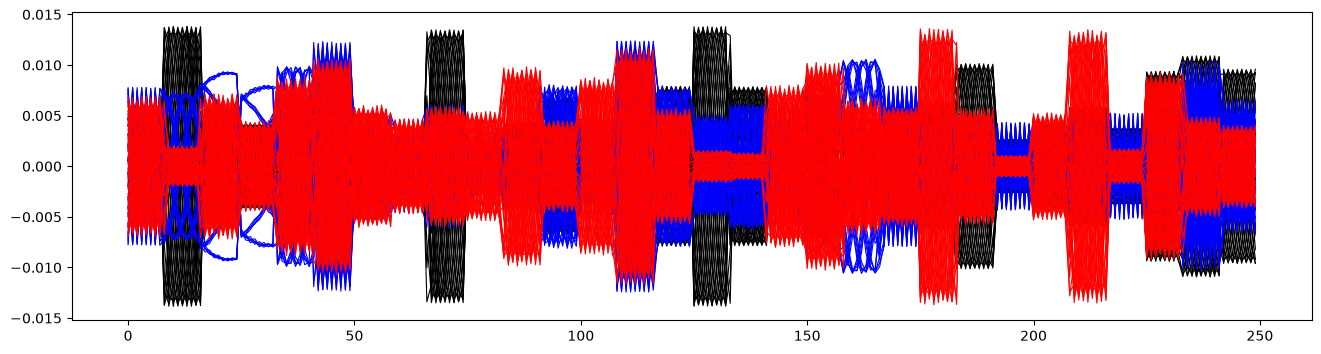

In [14]:
fig, ax = plt.subplots(1, figsize=(16,4))
lw=0.8
ax.plot(x_nosc, lw=lw, c='k', label='No SC')
ax.plot(x_xsuite, lw=lw, c='b', label='Xsuite')
ax.plot(x_mycode, lw=lw, c='r', label='My code')
#ax.legend()
plt.show()

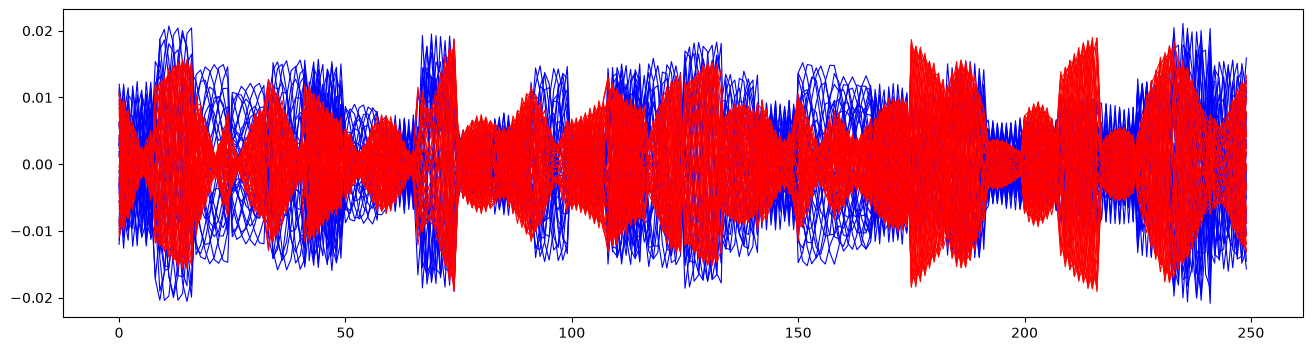

In [15]:
fig, ax = plt.subplots(1, figsize=(16,4))
lw=0.8
ax.plot(x_xsuite-x_nosc, lw=lw, c='b', label='Xsuite')
ax.plot(x_mycode-x_nosc, lw=lw, c='r', label='My code')
#ax.legend()
plt.show()

In [9]:
sc_xsuite = [
    el for name, el in line_xsuite.element_dict.items()
    if 'SpaceCharge' in type(el).__name__
]
sc_mycode = [
    el for name, el in line_mycode.element_dict.items()
    if 'SpaceCharge' in type(el).__name__
]

In [10]:
sc_xsuite[0]

SpaceChargeBiGaussian(longitudinal_profile=LongitudinalProfileQGaussian(number_of_particles=1.53e+26), fieldmap=BiGaussianFieldMap(mean_x=4.82e-11, mean_y=-4.2e-28, sigma_x=0.00516, sigma_y=0.00389, min_sigma_diff=1e-10), length=8.17, z_kick_num_integ_per_sigma=np.int64(0), shift_x=0, shift_y=0, shift_s=0, rot_s_rad=0, rot_x_rad=0, rot_y_rad=0, rot_s_rad_no_frame=0, rot_shift_anchor=0)

In [11]:
sc_mycode[0]

SpaceChargeFree(element_length=8.17, line_density=6.12e+09, mean_x=4.82e-11, mean_y=-4.2e-28, sigma_x=0.00516, sigma_y=0.00389, shift_x=0, shift_y=0, shift_s=0, rot_s_rad=0, rot_x_rad=0, rot_y_rad=0, rot_s_rad_no_frame=0, rot_shift_anchor=0)

In [12]:
test_particle = line.build_particles(x=2e-5, y=0, px=0, py=0)

sc_xsuite[0].track(test_particle)
print(test_particle.px)
print(test_particle.py)


Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
[3.92301909e-07]
[1.13344277e-17]


In [13]:
test_particle = line.build_particles(x=2e-5, y=0, px=0, py=0)

sc_mycode[0].track(test_particle)
print(test_particle.px)
print(test_particle.py)

[3.92301913e-07]
[0.]
